In [26]:
from langchain.chat_models import init_chat_model




# openrouter model for subagents 
openrouter_model = init_chat_model(
    "openrouter:google/gemini-2.5-flash"
)

# groq model for deepagents
groq_model = init_chat_model(
    "groq:openai/gpt-oss-20b"
)

In [ ]:
from langchain.tools import tool
from langchain.agents.middleware import TodoListMiddleware
from langchain_tavily import TavilySearch
from langchain.agents import create_agent

from deepagents import CompiledSubAgent, create_deep_agent
from deepagents.backends import StateBackend

from langgraph.checkpoint.memory import InMemorySaver
from typing import Dict, Any 

@tool
def web_search(query: str, max_results: int = 1,include_answer: bool = True, include_raw_content: bool = False)->Dict[str, Any]:
    """
    A Web searching tool
    returns a dictonary of results
    """
    tool = TavilySearch(
        max_results=max_results,
        topic="general",
        include_answer=include_answer,
        include_raw_content=include_raw_content,
        search_depth="basic",
    )
    return tool.invoke(query)

# create_agent returs a compiled graph
custom_graph = create_agent(
    model = openrouter_model,
    system_prompt="You are a data analysis specialist. Use available tools when necessary.",
    tools=[web_search]
)


# wrap the compiled graph to assign its name, description and runnable graph anf communication between subagents and deepagents
subagent = CompiledSubAgent(
    name="data-analyzer",
    description="MANDATORY for any market research, pricing metrics, cost lookups, or competitive analysis tasks. Analyzes numerical data, performs calculations",
    runnable=custom_graph
)


# register with create_deepagent
deepagent = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    subagents=[subagent],
    middleware=[TodoListMiddleware()],
    system_prompt=(
        "You are a strict task coordinator. You possess no internal research capabilities.\n\n"
        "WORKFLOW RULES:\n"
        "1. BEFORE doing anything else, you MUST use the `write_todos` tool to write out a todo list for the user's request.\n"
        "2. For any request regarding market analysis, costs, or domain research, you MUST call the `task()` tool with subagent_type='data-analyzer'.\n"
        "3. Once the subagent tool returns a result, update the todo item to completed using `write_todos` and relay the EXACT response directly to the user without adding supplementary figures."
    )
)  
deepagent

In [ ]:
resp = deepagent.invoke({
    'messages': "Reserach about LLM Gateways and provide me a detailed summary."
},config={
    "configurable":{
        "thread_id": "sub-1"
        
    }
}
)

In [ ]:
for m in resp["messages"]:
    m.pretty_print()

In [ ]:
# Test the worker independently
worker_result = custom_graph.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "Research LLM Gateways. "
                "Explain their architecture, benefits, "
                "limitations and popular implementations."
            )
        }
    ]
})

# Inspect the actual messages
for message in worker_result["messages"]:
    print("\nType:", type(message).__name__)
    print("Content:", message.content)

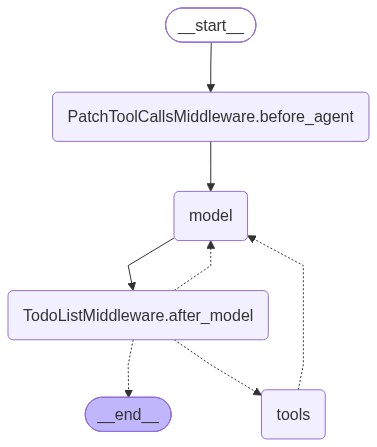

In [30]:
from pydantic import BaseModel, Field, HttpUrl
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware

class ResearchFindings(BaseModel):
    """Structured Findings for research tasks"""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="confidence Score from 0 to 1")
    sources: list[HttpUrl] = Field(min_length=3, description="List of source URL's")
    
research_subagent_dict = {
    "name": "researcher",
    "description": "Research the given topic and return structured results",
    "system_prompt": """Research the given topic throughly and return your findings
    You MUST format your final response strictly as a JSON object matching this schema:
        {
            "summary": "string summary",
            "confidence": 0.95,
            "sources": ["https://example.com"]
        }
    """,
    "tools": [web_search],
    "model": groq_model
}

d_agent = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    name="deepagent",
    middleware=[TodoListMiddleware()],
    system_prompt="""
        You are a research coordinator responsible for delegating tasks and presenting findings.

        WORKFLOW:

        Create a todo list.

        Delegate research tasks.

        Inspect responses for sufficient evidence.

        Request investigation into missing gaps.

        Complete todos only after verifying results.

        RULES:

        Do not invent facts, statistics, claims, or citations.

        Preserve source URLs and evidence; distinguish verified facts from uncertain findings.

        Report insufficient research when limitations exist; do not assume completeness just because a subagent responded.
        """,
    subagents=[research_subagent_dict]
)
d_agent

In [ ]:
resp = d_agent.invoke({
        'messages': "Reserach about LLM Gateways and provide me a detailed summary."
    },config={
        "configurable":{
            "thread_id": "a2"
            
        }
    }
)

In [33]:
for m in resp["messages"]:
    m.pretty_print()

================================ Human Message =================================

Reserach about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================
Name: deepagent
Tool Calls:
  task (fc_9da67cff-e109-4058-a60c-494b9051b381)
 Call ID: fc_9da67cff-e109-4058-a60c-494b9051b381
  Args:
    description: Research LLM Gateways: gather information on what they are, use cases, architecture, key providers, pros/cons, recent developments, and any notable examples. Return a structured summary with citations and URLs.
    subagent_type: researcher
================================= Tool Message =================================
Name: task

{
  "summary": "LLM gateways are middleware layers that sit between applications and one or more large‑language‑model (LLM) providers, offering a single, unified API for routing, authentication, cost tracking, fail‑over, and observability. They allow developers to switch or combine model

In [36]:
for event in d_agent.stream({
        'messages': "Research about the latest news about BMW m5"
    },config={
        "configurable":{
            "thread_id": "a2"
            
        }
    }
):
    for node_name, node_output in event.items():
        print(f"\n--- Node: {node_name} ---")
        if "messages" in node_output:
            latest_msg = node_output["messages"][-1]
            print(latest_msg.content)


--- Node: PatchToolCallsMiddleware.before_agent ---


TypeError: argument of type 'NoneType' is not iterable

In [38]:
config = {"configurable": {"thread_id": "1"}}
inputs = {"messages": "Research about LLM Gateways and provide me a detailed summary."}

for event in d_agent.stream(inputs, config=config, stream_mode="updates"):
    for node_name, node_output in event.items():
        print(f"\n--- Node: {node_name} ---")
        if isinstance(node_output, dict) and "messages" in node_output:
            if "messages" in node_output:
                latest_msg = node_output["messages"][-1]
                print(latest_msg.content)
        else:
            print(node_output)


--- Node: PatchToolCallsMiddleware.before_agent ---
None

--- Node: model ---


--- Node: TodoListMiddleware.after_model ---
None

--- Node: tools ---
No files found

--- Node: model ---


--- Node: TodoListMiddleware.after_model ---
None

--- Node: tools ---
Updated todo list to [{'content': 'Research LLM Gateways and gather sources', 'status': 'in_progress'}]

--- Node: model ---


--- Node: TodoListMiddleware.after_model ---
None

--- Node: tools ---
No files found

--- Node: model ---


--- Node: TodoListMiddleware.after_model ---
None

--- Node: tools ---
# LLM Gateways – A Structured Overview  

**LLM Gateways** are middleware layers that expose one or more large‑language‑model (LLM) services to downstream applications, providing a standardized API surface, security, scalability, and observability.  They sit between the “LLM provider” (OpenAI, Anthropic, Google, Azure, AWS, etc.) and the “consumer” (chat‑bots, data‑extraction pipelines, code‑generation tools, etc.).  Below is a 

In [ ]:
config = {"configurable": {"thread_id": "1a"}}
inputs = {"messages": "research and answer what is the current News of AI."}

for event in d_agent.stream(inputs, config=config, stream_mode="updates"):
    for node_name, node_output in event.items():
        # Skip nodes that produce no output state
        if not node_output or not isinstance(node_output, dict):
            continue

        if "messages" in node_output and node_output["messages"]:
            latest_msg = node_output["messages"][-1]
            
            # Print non-empty content
            if latest_msg.content:
                print(latest_msg.content)